# Stage 08: Scoring Pipeline

Score holdout, new data, or production data using saved encoder and model

In [1]:
config_path = 'config/car_coll/v1'
score_name = 'holdout'

In [2]:
# Parameters
config_path = "config/car_coll/v1"


In [3]:
import pandas as pd
import numpy as np
import xgboost as xgb
import yaml, os, sys, joblib
from pathlib import Path
sys.path.insert(0, str(Path.cwd() / 'lib'))
from utils import setup_notebook_environment
from preprocessing import condition_data
print('######## STAGE 08: SCORING ########')
project_root = setup_notebook_environment()

######## STAGE 08: SCORING ########


In [4]:
# Get machine config
pc_num = open("current.pc").read().strip()
pc_id = f"PC{pc_num}"

with open(f'{config_path}/config.yaml', 'r') as f:
    cfg = yaml.safe_load(f)
output_base = cfg['machines'][pc_id]['paths']['output_path']
score_cfg = cfg['scoring'][score_name]
print(f'Scoring: {score_name}')
print(f'Has target: {score_cfg.get("has_target", False)}')

Scoring: holdout
Has target: True


In [5]:
# Load data based on source type
print(f'\n* Loading data...')

if score_cfg['source'] == 'master':
    # Holdout scoring: Load master + aux, join, filter by fold
    print(f"  Source: master file with fold filter")
    
    # Load aux data (has fold column)
    aux_path = cfg['machines'][pc_id]['paths']['aux_data_path']
    aux_file = cfg['data']['aux_file']
    fold_col = cfg['data']['fold_column']
    join_key = cfg['data']['join_key']
    
    print(f"  Loading aux: {aux_path}/{aux_file}")
    aux_data = pd.read_parquet(f'{aux_path}/{aux_file}')
    
    # Filter aux to requested folds
    needed_folds = score_cfg['folds']
    aux_filtered = aux_data[aux_data[fold_col].isin(needed_folds)]
    print(f"  Filtered aux to folds {needed_folds}: {aux_filtered.shape[0]:,} rows")
    
    # Load master data
    master_path = cfg['machines'][pc_id]['paths']['master_data_path']
    master_file = cfg['data']['master_file']
    print(f"  Loading master: {master_path}/{master_file}")
    
    # Load all columns from master
    master_data = pd.read_parquet(f'{master_path}/{master_file}')
    print(f"  Loaded master: {master_data.shape}")
    
    # Join master with aux (to get fold)
    # Join master with aux (fold + target if needed)
    aux_cols = [join_key, fold_col]
    if score_cfg.get('has_target', False):
        target = cfg['experiment']['target']
        if target in aux_filtered.columns:
            aux_cols.append(target)
            print(f'  Including target from aux: {target}')
        # Source columns for combined target (e.g. pp_bi, pp_pd); exposures come from master
        from utils import combine_source_columns
        aux_cols += [c for c in combine_source_columns(cfg) if c in aux_filtered.columns and c not in aux_cols and c not in master_data.columns]
    df = master_data.merge(aux_filtered[aux_cols], on=join_key, how='inner')
    from utils import add_combined_columns
    df = add_combined_columns(df, cfg)
    print(f"  After join: {df.shape}")
    print(f"  Fold distribution: {df[fold_col].value_counts().sort_index().to_dict()}")
    
elif score_cfg['source'] == 'file':
    # New data scoring: Load file directly
    print(f"  Source: file (new data)")
    data_path = score_cfg.get('data_dir', cfg['machines'][pc_id]['paths']['master_data_path'])
    file_name = score_cfg['file']
    print(f"  Loading: {data_path}/{file_name}")
    df = pd.read_parquet(f'{data_path}/{file_name}')
    print(f"  Loaded: {df.shape}")
    
else:
    raise ValueError(f"Unknown source type: {score_cfg['source']}")

print(f'\n* Data loaded: {df.shape}')

# Save target and exposure for metrics (if available)
target_values = None
exposure_values = None
if score_cfg.get('has_target', False):
    target = cfg['experiment']['target']
    exposure = cfg['experiment']['exposure']
    if target in df.columns:
        target_values = df[target].copy()
        print(f'  Saved target for metrics: {target}')
    if exposure in df.columns:
        exposure_values = df[exposure].copy()
        print(f'  Saved exposure for metrics: {exposure}')


* Loading data...
  Source: master file with fold filter
  Loading aux: /Users/Mach/dev/aps/data/2026_Dmodel_data/alldata/car/car_with_dep_factor_fold.parquet


  Filtered aux to folds [8, 9, 10]: 6,808,928 rows
  Loading master: /Users/Mach/dev/aps/data/2026_Dmodel_data/alldata/car/master_dataset_car.parquet


  Loaded master: (22705842, 406)
  Including target from aux: pp_coll


  After join: (6808928, 408)
  Fold distribution: {8: 2271212, 9: 2272319, 10: 2265397}

* Data loaded: (6808928, 408)
  Saved target for metrics: pp_coll
  Saved exposure for metrics: ee_coll_imps


In [6]:
# Apply loss cap and exposure floor (match training pipeline)
print(f'\n* Applying loss cap and exposure floor...')
target = cfg['experiment']['target']
exposure = cfg['experiment']['exposure']
loss_cap = cfg['experiment'].get('loss_cap', None)
loss_type = cfg['experiment'].get('loss_type', 'bi')
exposure_floor = cfg['experiment'].get('exposure_floor', None)

# Only apply if target exists (has_target=True)
if score_cfg.get('has_target', False) and target in df.columns:
    from model_utils import apply_loss_cap_single
    df = apply_loss_cap_single(
        df,
        loss_cap=loss_cap,
        target_col=target,
        exposure_col=exposure,
        exposure_floor=exposure_floor,
        verbose=True
    )
    # Metrics/charts use the same capped target and floored exposure as training
    target_values_uncapped = (target_values * exposure_values).loc[df.index] / df[exposure]
    target_values = df[target].copy()
    exposure_values = df[exposure].copy()
else:
    print(f'  Skipping loss cap (no target in data)')
    # Still apply exposure floor if needed
    if exposure_floor and exposure in df.columns:
        import numpy as np
        n_floor = (df[exposure] < exposure_floor).sum()
        df[exposure] = np.maximum(df[exposure], exposure_floor)
        if n_floor > 0:
            print(f'  Exposure floor ({exposure_floor}): {n_floor:,} records adjusted')

print(f'  Shape after loss cap/floor: {df.shape}')


* Applying loss cap and exposure floor...


  Filter: Dropping 2,128,496 records where ee_coll_imps = 0


  Exposure floor (0.0833): 75,760 records adjusted
  Final: 4,680,432 records
  Shape after loss cap/floor: (4680432, 408)


In [7]:
# Preserve target and exposure before conditioning
print(f'\n* Conditioning...')
target = cfg['experiment']['target']
exposure = cfg['experiment']['exposure']

# Save target/exposure if they exist
target_data = None
exposure_data = None
if target in df.columns:
    target_data = df[target].copy()
    print(f'  Preserved target: {target}')
if exposure in df.columns:
    exposure_data = df[exposure].copy()
    print(f'  Preserved exposure: {exposure}')

# Apply conditioning (this may drop target/exposure)
df = condition_data(df, cfg)
print(f'  After conditioning: {df.shape}')

# Restore target/exposure if they were present
if target_data is not None:
    df[target] = target_data
    print(f'  Restored target: {target}')
if exposure_data is not None:
    df[exposure] = exposure_data
    print(f'  Restored exposure: {exposure}')

print(f'  Final shape: {df.shape}')


* Conditioning...
  Preserved target: pp_coll
  Preserved exposure: ee_coll_imps


  After conditioning: (4680432, 408)
  Restored target: pp_coll
  Restored exposure: ee_coll_imps
  Final shape: (4680432, 408)


In [8]:
# Drop auxiliary columns before encoding
print(f'\n* Dropping auxiliary columns...')
aux_cols = ['fold']  # Only drop fold; keep vin_date for GLM lookup and output joining
cols_to_drop = [c for c in aux_cols if c in df.columns]
if cols_to_drop:
    df = df.drop(columns=cols_to_drop)
    print(f'  Dropped: {cols_to_drop}')
else:
    print(f'  No aux columns to drop')
print(f'  Data shape: {df.shape}')



* Dropping auxiliary columns...
  Dropped: ['fold']
  Data shape: (4680432, 407)


In [9]:
# Load encoders and encoding summary
print(f'\n* Loading encoder...')
import joblib
with open(f'{output_base}/models/04c_encoders.pkl', 'rb') as f:
    encoders = joblib.load(f)

encoding_summary = pd.read_csv(f'{output_base}/results/04c_encoding_summary.csv')
print(f'  Loaded {len(encoders)} encoders and encoding summary')

# Encode features
print(f'\n* Encoding...')
from feature_encoder import apply_saved_encoders
df_encoded = apply_saved_encoders(df, encoders, encoding_summary)
print(f'  Encoded: {df_encoded.shape}')

# Compare with training columns and fix mismatch
X_train_ref = pd.read_parquet(f'{output_base}/data/04c_train_encoded.parquet')
train_cols = set(X_train_ref.columns)
encoded_cols = set(df_encoded.columns)
extra_in_encoded = encoded_cols - train_cols
missing_in_encoded = train_cols - encoded_cols
if extra_in_encoded:
    print(f'  [!] EXTRA columns: {extra_in_encoded}')
    df_encoded = df_encoded.drop(columns=list(extra_in_encoded))
    print(f'  Dropped extra. New shape: {df_encoded.shape}')
if missing_in_encoded:
    print(f'  [!] MISSING columns: {missing_in_encoded}')



* Loading encoder...
  Loaded 24 encoders and encoding summary

* Encoding...


[OK] Applied saved encoders: (4680432, 147)
  Encoded: (4680432, 147)


In [10]:
# Load model
print(f'\n* Loading model...')
model_file = f'{output_base}/models/05c_model.json'
model = xgb.XGBRegressor()
model.load_model(model_file)
print(f'  Model loaded: {model_file}')

# Validate features match
from model_validation import validate_features_match
validate_features_match(model, df_encoded, 'df_encoded')

# Get target method and predict
target_method = cfg.get('model', {}).get('target_method', 'direct')
print(f'\n* Predicting (method={target_method})...')
if target_method == 'residual':
    from model_utils import load_glm_for_scoring, predict_with_transform
    glm_preds, matched_idx = load_glm_for_scoring(df, cfg, score_cfg, pc_id, target_method)
    
    # Filter data to rows with GLM predictions
    if matched_idx is not None:
        df = df.loc[matched_idx]
        df_encoded = df_encoded.loc[matched_idx]
    
    _, predictions = predict_with_transform(model, df_encoded, glm_preds, target_method)
    # Filter out NaN predictions
    if predictions.isna().any():
        print(f"  Filtering {predictions.isna().sum()} NaN predictions")
        valid_mask = ~predictions.isna()
        predictions = predictions[valid_mask]
    # Align df to predictions index before assignment
    df = df.loc[predictions.index].copy()  # Keep only rows we predicted for (copy to avoid fragmentation)
    df['prediction'] = predictions.values
    df['glm_pred'] = glm_preds.loc[df.index].values
    
    # Update target_values and exposure_values to match filtered df
    if target_values is not None:
        target_values = target_values.loc[df.index]
    if exposure_values is not None:
        exposure_values = exposure_values.loc[df.index]
else:
    df['prediction'] = model.predict(df_encoded)
print(f'  Mean: {df["prediction"].mean():.2f}')

# Validate predictions
from model_validation import validate_predictions
validate_predictions(df['prediction'].values, df)



* Loading model...
  Model loaded: output/car_coll/v1/models/05c_model.json

* Feature Validation:
  Model expects: 147 features
  df_encoded has: 147 features
  ✓ Feature names match
  ✓ Validation passed


* Predicting (method=residual)...


  Removed 4,543 rows (0.10%) without GLM predictions
Loaded GLM predictions: mean=228.5962, std=124.9019


  Mean: 231.76

* Prediction Validation:
  Shape: (4675889,)
  Min: 2.59
  Max: 3947.58
  Mean: 231.76
  Median: 196.74
  ✓ Predictions valid



True

In [11]:
print(f'\n* Saving...')
output_dir = f'{output_base}/scoring/{score_name}'
os.makedirs(output_dir, exist_ok=True)
# Reset index to make vin_date a column for portability
df.reset_index().to_parquet(f'{output_dir}/predictions.parquet', index=False)
print(f'  Saved: scoring/{score_name}/predictions.parquet')


* Saving...


  Saved: scoring/holdout/predictions.parquet


In [12]:
# Calculate metrics (if target available)
if score_cfg.get('has_target', False):
    from sklearn.metrics import mean_absolute_error, mean_squared_error
    import numpy as np
    import pandas as pd
    
    if target_values is None or exposure_values is None:
        print('\n[!] Warning: Target/exposure not available for metrics')
    else:
        print(f'\n* Calculating metrics...')
        
        # Create aligned series and check for NaN
        metrics_df = pd.DataFrame({
            'target': target_values,
            'prediction': df['prediction'],
            'exposure': exposure_values
        })
        
        print(f'  Total rows: {len(metrics_df):,}')
        
        # Check for NaN
        nan_mask = metrics_df.isna().any(axis=1)
        n_nan = nan_mask.sum()
        if n_nan > 0:
            print(f'  [!] Found {n_nan:,} rows with NaN values')
            print(f'    NaN in target: {metrics_df["target"].isna().sum():,}')
            print(f'    NaN in prediction: {metrics_df["prediction"].isna().sum():,}')
            print(f'    NaN in exposure: {metrics_df["exposure"].isna().sum():,}')
            print(f'  Filtering out NaN rows...')
            metrics_df = metrics_df[~nan_mask]
        
        print(f'  Valid rows for metrics: {len(metrics_df):,}')
        
        # Calculate metrics on clean data
        mae = mean_absolute_error(
            metrics_df['target'],
            metrics_df['prediction'],
            sample_weight=metrics_df['exposure']
        )
        rmse = np.sqrt(mean_squared_error(
            metrics_df['target'],
            metrics_df['prediction'],
            sample_weight=metrics_df['exposure']
        ))
        
        print(f'  MAE: {mae:.4f}')
        print(f'  RMSE: {rmse:.4f}')
        
        # Save metrics
        metrics = {
            'score_name': score_name,
            'mae': float(mae),
            'rmse': float(rmse),
            'n_rows': len(metrics_df),
            'n_rows_with_nan': int(n_nan) if n_nan > 0 else 0
        }
        
        with open(f'{output_dir}/metrics.yaml', 'w') as f:
            yaml.dump(metrics, f)
        print(f'  Metrics saved to {output_dir}/metrics.yaml')
else:
    print('\n* No target available (has_target=False)')



* Calculating metrics...
  Total rows: 4,675,889
  Valid rows for metrics: 4,675,889
  MAE: 432.2674
  RMSE: 6438.6221
  Metrics saved to output/car_coll/v1/scoring/holdout/metrics.yaml


In [13]:
# Loss cap / exposure floor already applied in cell 5; align uncapped target to scored rows
if score_cfg.get('has_target', False) and target_values is not None:
    target_values_uncapped = target_values_uncapped.loc[target_values.index]
else:
    target_values_uncapped = None



* Creating lift chart...
  Creating chart for 4,675,889 rows...
  [STEP 1] Creating column list...
  [STEP 1] Done in 0.000s
  [STEP 2] Extracting 5 columns from 4,675,889 rows...
  [STEP 2] Done in 0.038s
  [STEP 3a] Sorting by prediction (this may take 1-2 min for 2.7M rows)...


  [STEP 3a] sort_values done in 0.6s
  [STEP 3b] Resetting index...
  [STEP 3b] Done in 0.000s
  [STEP 4] Calculating cumulative weight...
  [STEP 4] Done in 0.047s
  [STEP 5] Aggregating by decile...
  [STEP 5] Done in 0.137s
  Creating plot...


  Plot created in 0.1s
  TOTAL TIME: 0.9s
  Saved: output/car_coll/v1/scoring/holdout/lift_chart.png


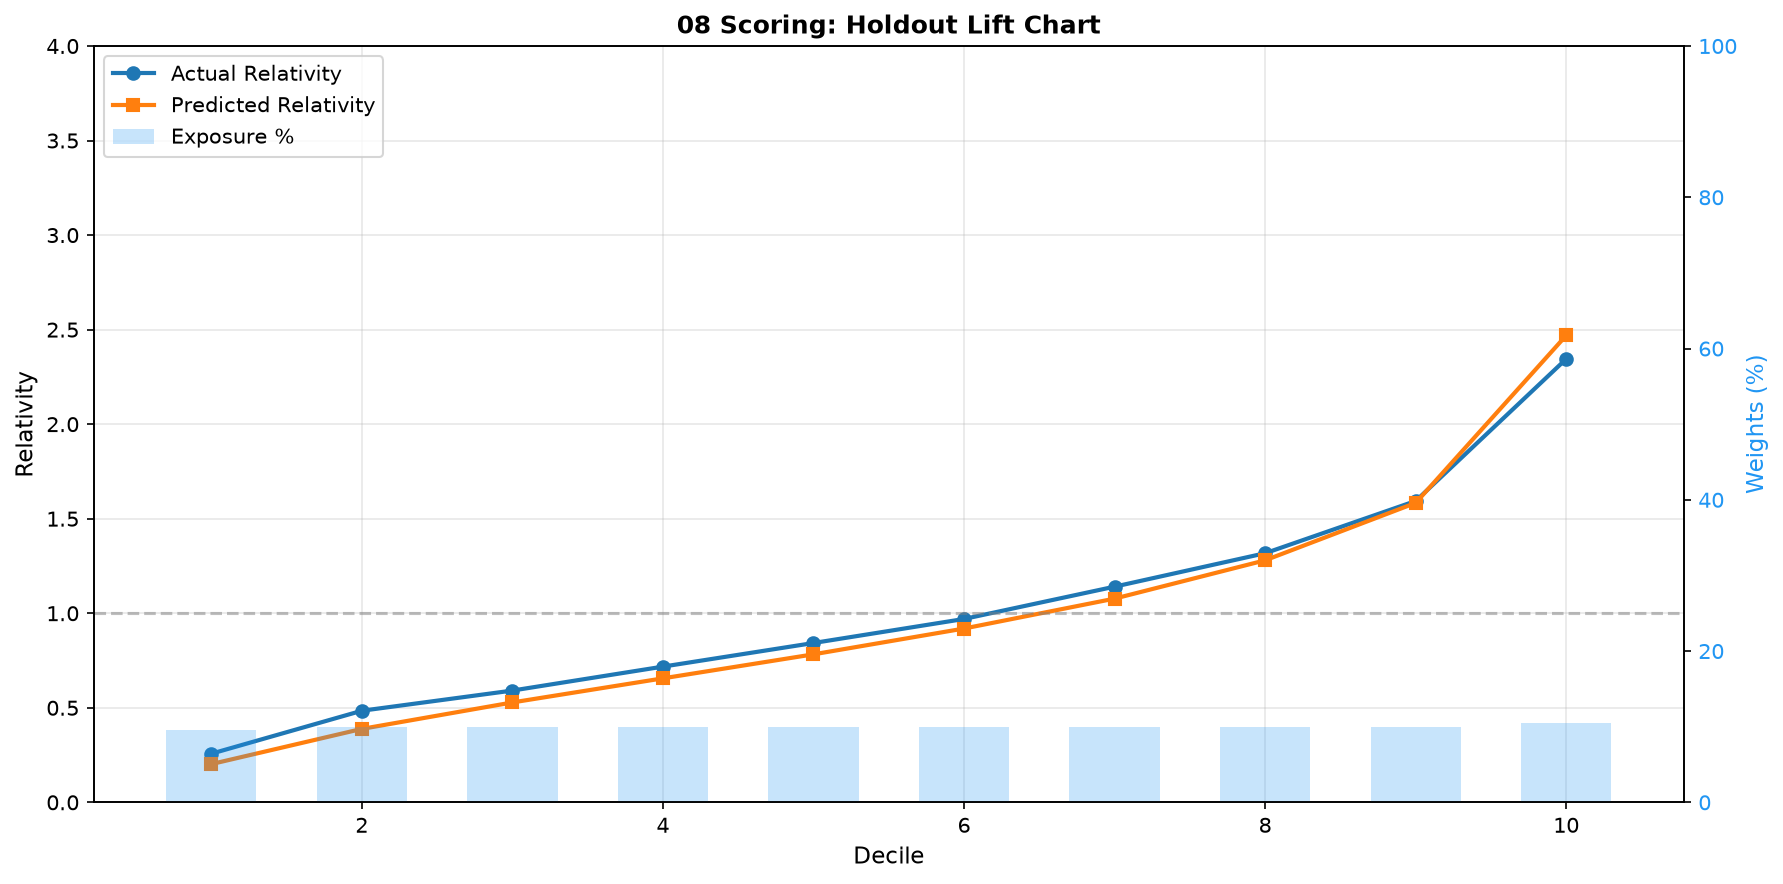


Decile summary:
 decile  n_records  ee_coll_imps  incurred_act  incurred_pred  act_ee_weigh_avg  act_simple_avg  pred_ee_weigh_avg  pred_simple_avg
      1     398984 293462.577279  1.654537e+07   1.300334e+07         56.379830       41.468756          44.310059        32.591141
      2     427987 308909.427252  3.280291e+07   2.630022e+07        106.189409       76.644640          85.138933        61.450976
      3     439611 308909.074264  4.003385e+07   3.577888e+07        129.597505       91.066523         115.823332        81.387586
      4     449810 308909.035576  4.860865e+07   4.440918e+07        157.355878      108.064855         143.761355        98.728756
      5     458427 308908.562389  5.706801e+07   5.301278e+07        184.740780      124.486579         171.613165       115.640606
      6     466450 308908.997773  6.567582e+07   6.225111e+07        212.605728      140.799276         201.519266       133.457208
      7     474547 308908.963605  7.724807e+07   7.296362e+

In [14]:
# Create lift chart (if target available)
if score_cfg.get('has_target', False) and target_values is not None:
    from lift_chart_fast import generate_scoring_lift_chart
    
    target = cfg['experiment']['target']
    exposure = cfg['experiment']['exposure']
    
    # Generate capped lift chart
    table = generate_scoring_lift_chart(
        df['prediction'],
        target_values,
        exposure_values,
        exposure,
        output_dir,
        output_base,
        score_name=score_name
    )
else:
    print(f'\\n* Skipping lift chart (no target available)')



* Creating holdout GBM ratio lift chart...


  [STEP 1] Creating column list...
  [STEP 1] Done in 0.000s
  [STEP 2] Extracting 5 columns from 4,675,889 rows...
  [STEP 2] Done in 0.026s
  [STEP 3a] Sorting by prediction (this may take 1-2 min for 2.7M rows)...


  [STEP 3a] sort_values done in 0.6s
  [STEP 3b] Resetting index...
  [STEP 3b] Done in 0.001s
  [STEP 4] Calculating cumulative weight...
  [STEP 4] Done in 0.046s
  [STEP 5] Aggregating by decile...
  [STEP 5] Done in 0.133s
  Creating plot...


  Plot created in 0.0s
  TOTAL TIME: 0.8s
  Saved: output/car_coll/v1/scoring/holdout/lift_chart_ratio.png


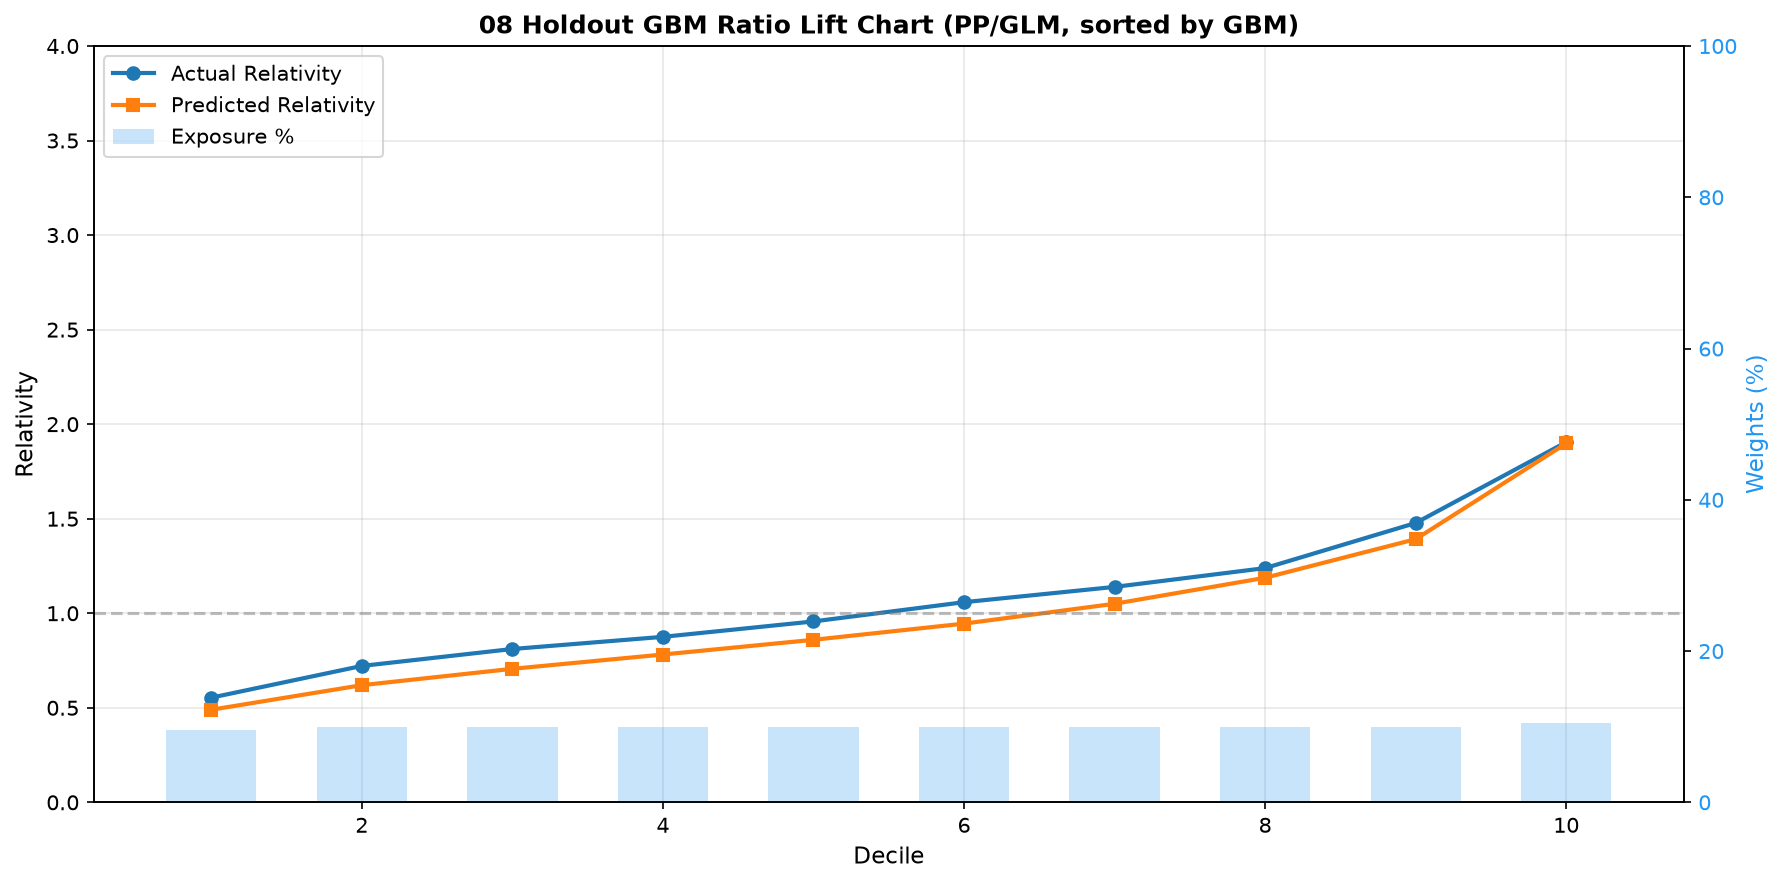


Holdout ratio summary:
 decile  n_records  ee_coll_imps  incurred_act  incurred_pred  act_ee_weigh_avg  act_simple_avg  pred_ee_weigh_avg  pred_simple_avg
      1     409286 293462.947776 163794.718460  144891.925353          0.558144        0.400196           0.493732         0.354011
      2     434097 308908.724648 224685.248945  192986.610047          0.727352        0.517592           0.624737         0.444570
      3     440973 308908.894204 252596.865009  219937.394170          0.817707        0.572817           0.711981         0.498755
      4     450732 308909.656760 272617.158715  243504.804823          0.882514        0.604832           0.788272         0.540243
      5     457941 308908.771040 297981.776851  267731.100655          0.964627        0.650699           0.866700         0.584641
      6     465748 308908.901618 329684.171933  294387.359016          1.067254        0.707860           0.952991         0.632074
      7     476347 308908.805339 354874.717879  3270

In [15]:
# Ratio lift chart (residual method only)
from lift_chart_fast import generate_scoring_ratio_lift_chart
if score_cfg.get('has_target', False) and target_values is not None and 'glm_pred' in df.columns:
    table_r = generate_scoring_ratio_lift_chart(df['prediction'], target_values, df['glm_pred'], exposure_values,
                                                exposure, output_dir, output_base, score_name=score_name)
else:
    print('\n* Skipping ratio chart (no target or not residual method)')


In [16]:
# Calculate actuarial metrics (if target available)
if score_cfg.get('has_target', False) and target_values is not None:
    from hpo_metrics import compute_fit_quality, compute_model_power
    
    print(f'\n* Calculating actuarial metrics...')
    
    # Use clean data (no NaN)
    if 'metrics_df' in locals():
        clean_target = metrics_df['target'].values
        clean_pred = metrics_df['prediction'].values
        clean_exposure = metrics_df['exposure'].values
    else:
        # Fallback if metrics_df not created - use aligned dataframe
        temp_df = pd.DataFrame({
            'target': target_values,
            'prediction': df['prediction'],
            'exposure': exposure_values
        })
        temp_df = temp_df.dropna()
        clean_target = temp_df['target'].values
        clean_pred = temp_df['prediction'].values
        clean_exposure = temp_df['exposure'].values
    
    fit_quality = compute_fit_quality(clean_target, clean_pred, clean_exposure)
    model_power = compute_model_power(clean_target, clean_pred, clean_exposure)
    
    print(f'\n* Actuarial Metrics ({score_name}):')
    print(f'    Fit Quality:  {fit_quality:.4f}')
    print(f'    Model Power:  {model_power:.4f}')
    
    # Add to saved metrics if it exists
    if 'metrics' in locals():
        metrics['fit_quality'] = float(fit_quality)
        metrics['model_power'] = float(model_power)
        with open(f'{output_dir}/metrics.yaml', 'w') as f:
            yaml.dump(metrics, f)
        print(f'  Updated metrics.yaml')
else:
    print(f'\n* Skipping actuarial metrics (no target available)')



* Calculating actuarial metrics...



* Actuarial Metrics (holdout):
    Fit Quality:  0.9137
    Model Power:  0.4860
  Updated metrics.yaml



* Creating UNCAPPED lift chart...
  This shows model performance against actual (uncapped) losses

* Creating lift chart_uncapped...
  Creating chart for 4,675,889 rows...
  [STEP 1] Creating column list...
  [STEP 1] Done in 0.000s
  [STEP 2] Extracting 5 columns from 4,675,889 rows...
  [STEP 2] Done in 0.023s
  [STEP 3a] Sorting by prediction (this may take 1-2 min for 2.7M rows)...


  [STEP 3a] sort_values done in 0.6s
  [STEP 3b] Resetting index...
  [STEP 3b] Done in 0.000s
  [STEP 4] Calculating cumulative weight...
  [STEP 4] Done in 0.041s
  [STEP 5] Aggregating by decile...
  [STEP 5] Done in 0.158s


  Creating plot...
  Plot created in 0.1s
  TOTAL TIME: 0.9s
  Saved: output/car_coll/v1/scoring/holdout/lift_chart_uncapped.png


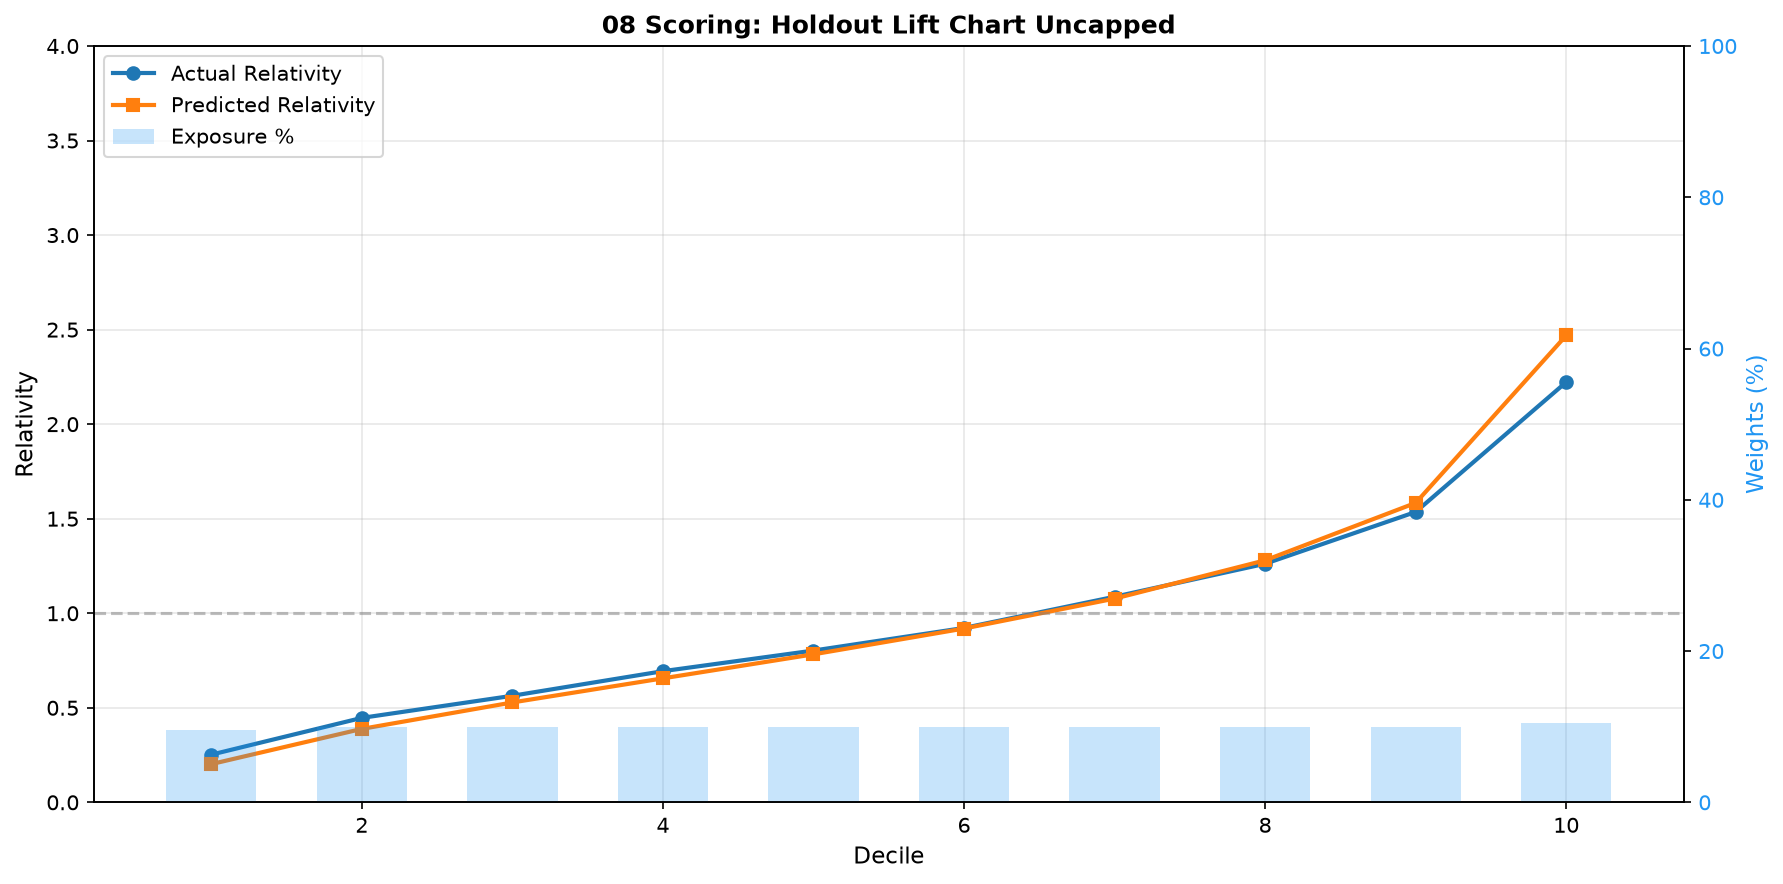


Decile summary:
 decile  n_records  ee_coll_imps  incurred_act  incurred_pred  act_ee_weigh_avg  act_simple_avg  pred_ee_weigh_avg  pred_simple_avg
      1     398984 293462.577279   16220991.50   1.300334e+07         55.274480       40.655744          44.310059        32.591141
      2     427987 308909.427252   30246993.22   2.630022e+07         97.915410       70.672692          85.138933        61.450976
      3     439611 308909.074264   38168500.79   3.577888e+07        123.559015       86.823352         115.823332        81.387586
      4     449810 308909.035576   46978939.42   4.440918e+07        152.080173      104.441741         143.761355        98.728756
      5     458427 308908.562389   54364422.98   5.301278e+07        175.988722      118.589051         171.613165       115.640606
      6     466450 308908.997773   62459431.10   6.225111e+07        202.193628      133.903808         201.519266       133.457208
      7     474547 308908.963605   73638920.68   7.296362e+

In [17]:
# Uncapped Lift Chart - Compare model predictions vs actual uncapped losses
if score_cfg.get('has_target', False) and target_values_uncapped is not None:
    from lift_chart_fast import generate_scoring_lift_chart
    
    target = cfg['experiment']['target']
    exposure = cfg['experiment']['exposure']
    
    print(f'\n* Creating UNCAPPED lift chart...')
    print(f'  This shows model performance against actual (uncapped) losses')
    
    # Generate uncapped lift chart
    table_uncapped = generate_scoring_lift_chart(
        df['prediction'],
        target_values_uncapped,
        exposure_values,
        exposure,
        output_dir,
        output_base,
        score_name=score_name,
        suffix='_uncapped'
    )
else:
    print(f'\n* Skipping uncapped lift chart (no target available)')
